# HarvestSafe pipeline demo

Walks the artifacts produced by `python main.py`. Cells call the same `src` loaders used by the entry script. Weather is read from the cache, so this notebook does not hit the Open-Meteo API and does not retrain the network.

Run `python main.py` once from the repository root before starting here.

In [1]:
import json
from pathlib import Path
import sys

import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.dataset import load_split
from src.fetch_weather import aggregate_weather
from src.ingest_nisr import load_nisr_yields

RAW_XLSX = ROOT / "data" / "raw" / "SAS 2025_Annual Tables.xlsx"
WEATHER_CSV = ROOT / "data" / "raw" / "rwanda_historical_weather.csv"
FEATURES_CSV = ROOT / "data" / "processed" / "merged_harvest_features.csv"
TRAIN_NPZ = ROOT / "data" / "processed" / "train_dataset.npz"
VAL_NPZ = ROOT / "data" / "processed" / "val_dataset.npz"
METRICS = ROOT / "runs" / "harvestsafe_metrics.json"

## 1. NISR Table 24

Maize and bean production in metric tons for the 30 districts. `total_vulnerable_yield_mt` is their sum.

In [2]:
yields = load_nisr_yields(RAW_XLSX)
print(f"{len(yields)} districts")
yields.sort_values("total_vulnerable_yield_mt", ascending=False).head(8)

30 districts


,district,maize_yield_mt,bean_yield_mt,total_vulnerable_yield_mt
24,Nyagatare,85406.559681,10753.849675,96160.409356
27,Kirehe,60970.130096,12972.375002,73942.505098
25,Gatsibo,41037.105222,13982.979550,55020.084772
26,Kayonza,34260.528191,9934.304358,44194.832549
28,Ngoma,30530.699883,10828.610209,41359.310092
21,Burera,20130.036023,10012.852029,30142.888052
23,Rwamagana,17831.649253,8606.063173,26437.712425
16,Rusizi,15312.245255,9823.541081,25135.786336


## 2. Harvest-window weather

Daily Open-Meteo archive rows for 15 December 2024 through 15 February 2025, aggregated to rainfall, heavy-rain days, mean humidity, and peak temperature.

In [3]:
daily = pd.read_csv(WEATHER_CSV)
weather = aggregate_weather(daily)
print(f"{len(daily)} daily rows, {daily['date'].min()} to {daily['date'].max()}")
weather.sort_values("total_harvest_rainfall_mm", ascending=False).head(8)

1890 daily rows, 2024-12-15 to 2025-02-15


,district,latitude,longitude,total_harvest_rainfall_mm,heavy_rain_days,mean_relative_humidity,peak_temperature_c
12,Rutsiro,-1.9417,29.3250,1030.9,39,84.603175,25.5
19,Gakenke,-1.6983,29.7850,332.9,12,81.539683,24.8
17,Nyamasheke,-2.3403,29.1467,328.7,10,82.412698,24.5
16,Rusizi,-2.4842,28.9075,321.9,12,84.190476,25.0
9,Muhanga,-2.0844,29.7531,295.5,14,80.698413,25.6
11,Karongi,-2.0603,29.3478,292.8,9,77.587302,26.0
5,Nyaruguru,-2.6972,29.5264,284.4,7,80.095238,24.0
3,Nyanza,-2.3516,29.7506,262.2,9,79.666667,25.8


Season A harvest-window rainfall for all 30 districts. Rutsiro, on the Congo–Nile crest, is several times wetter than the eastern districts.

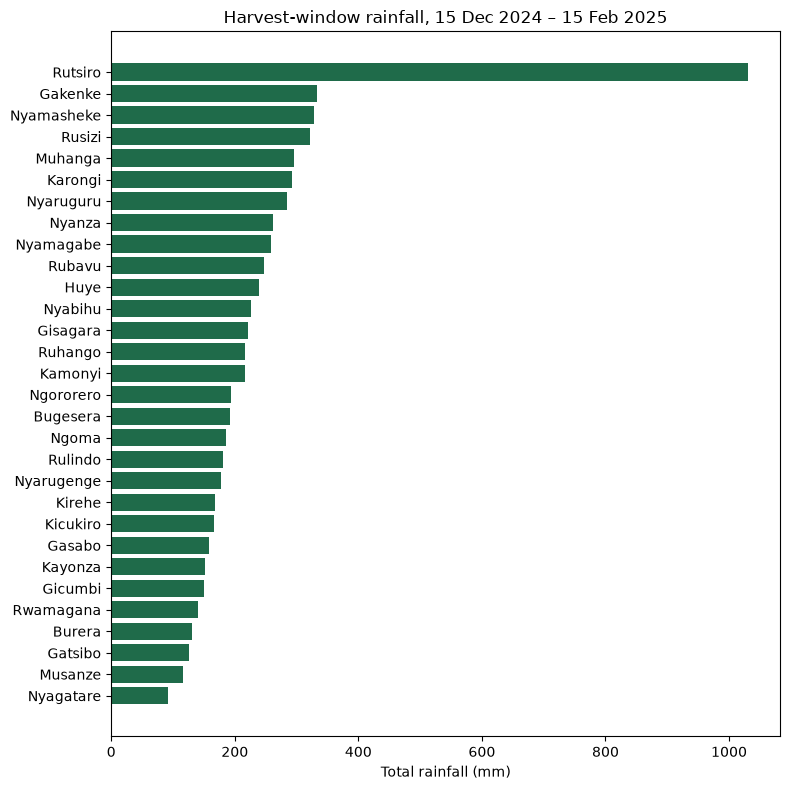

In [4]:
import matplotlib.pyplot as plt

ranked = weather.sort_values("total_harvest_rainfall_mm")
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(ranked["district"], ranked["total_harvest_rainfall_mm"], color="#1f6b4a")
ax.set_xlabel("Total rainfall (mm)")
ax.set_title("Harvest-window rainfall, 15 Dec 2024 – 15 Feb 2025")
fig.tight_layout()
plt.show()


## 3. Features and synthetic loss target

`post_harvest_loss_pct` is clipped to `[0.05, 0.48]`. It is a seeded function of moisture hazard, heavy-rain days, and log yield, not a measured NISR loss.

In [5]:
features = pd.read_csv(FEATURES_CSV)
print(features["post_harvest_loss_pct"].describe().round(4))
cols = [
    "district",
    "total_harvest_rainfall_mm",
    "heavy_rain_days",
    "mean_relative_humidity",
    "moisture_hazard_index",
    "log_yield_exposure",
    "post_harvest_loss_pct",
]
features.sort_values("post_harvest_loss_pct", ascending=False)[cols].head(10)

count    30.0000
mean      0.1363
std       0.0570
min       0.0819
25%       0.1108
50%       0.1296
75%       0.1400
max       0.4057
Name: post_harvest_loss_pct, dtype: float64


,district,total_harvest_rainfall_mm,heavy_rain_days,mean_relative_humidity,moisture_hazard_index,log_yield_exposure,post_harvest_loss_pct
12,Rutsiro,1030.9,39,84.603175,872.174127,9.411801,0.405746
16,Rusizi,321.9,12,84.190476,271.009143,10.132088,0.187954
19,Gakenke,332.9,12,81.539683,271.445603,9.997502,0.176404
3,Nyanza,262.2,9,79.666667,208.886000,9.837297,0.159027
27,Kirehe,167.2,3,75.063492,125.506159,11.211057,0.156935
11,Karongi,292.8,9,77.587302,227.175619,9.706309,0.156176
28,Ngoma,185.1,4,74.793651,138.443048,10.630077,0.144755
17,Nyamasheke,328.7,10,82.412698,270.890540,9.627643,0.140758
13,Rubavu,247.4,8,80.571429,199.333714,9.192637,0.137607
26,Kayonza,152.3,2,73.730159,112.291032,10.696386,0.136994


Distribution of the synthetic loss label. Most districts sit near 10–15 percent; Rutsiro is the right-hand outlier near 40 percent.

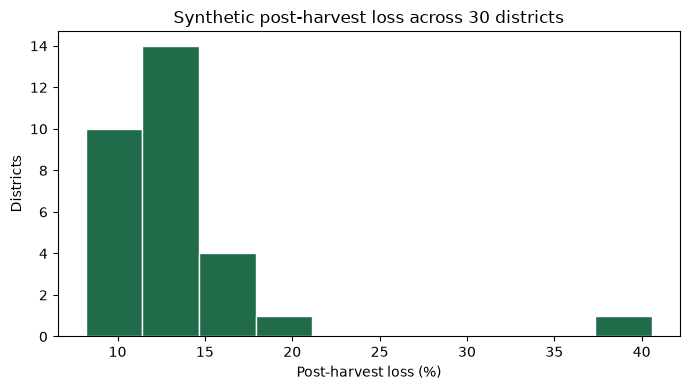

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(
    features["post_harvest_loss_pct"] * 100,
    bins=10,
    color="#1f6b4a",
    edgecolor="white",
)
ax.set_xlabel("Post-harvest loss (%)")
ax.set_ylabel("Districts")
ax.set_title("Synthetic post-harvest loss across 30 districts")
fig.tight_layout()
plt.show()


## 4. Arrays and the 1-epoch checkpoint

Training uses batches of 4. The metrics file is written by `src/train.py` next to the Keras checkpoint.

In [7]:
train = load_split(TRAIN_NPZ)
validation = load_split(VAL_NPZ)
print(f"train features: {train['features'].shape}  target: {train['target'].shape}")
print(f"val features: {validation['features'].shape}  target: {validation['target'].shape}")

metrics = json.loads(METRICS.read_text())
for key in ("epochs", "train_mse", "val_mse", "train_mae", "val_mae", "n_parameters", "train_batches"):
    print(f"{key}: {metrics[key]}")

train features: (24, 7)  target: (24, 1)
val features: (6, 7)  target: (6, 1)
epochs: 1
train_mse: 0.033061271688590445
val_mse: 0.008338338695466518
train_mae: 0.16255454098184904
val_mae: 0.07557591050863266
n_parameters: 865
train_batches: 6
